# Notebook 15.3 -- MNIST Data Generation using a GAN with Fully Connected Layers

In [12]:
# prerequisites
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import datasets, transforms
from torch.autograd import Variable
from torchvision.utils import save_image

# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

### Load the MNIST dataset

In [13]:
bs = 100

# MNIST Dataset
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.5,), std=(0.5,))])

train_dataset = datasets.MNIST(root='./data', train=True, transform=transform, download=True)
test_dataset = datasets.MNIST(root='./data', train=False, transform=transform, download=True)


# Data Loader (Input Pipeline)
train_loader = torch.utils.data.DataLoader(dataset=train_dataset, batch_size=bs, shuffle=True)
test_loader = torch.utils.data.DataLoader(dataset=test_dataset, batch_size=bs, shuffle=False)

### Define the Generator and Discriminator

In this example we will use a simple GAN with fully connected layers to generate MNIST digits. The generator will have 4 fully connected layers with 256, 512, 1024, and 784 neurons respectively. The discriminator will have 4 fully connected layers with 1024, 512, 256, and 1 neurons respectively.

We are also using the leaky ReLU activation function in the discriminator activation function in the generator. The generator will use the tanh activation function in the output layer.

In [14]:
class Generator(nn.Module):
    def __init__(self, g_input_dim, g_output_dim):
        super(Generator, self).__init__()       
        self.fc1 = nn.Linear(g_input_dim, 256)
        self.fc2 = nn.Linear(self.fc1.out_features, self.fc1.out_features*2)
        self.fc3 = nn.Linear(self.fc2.out_features, self.fc2.out_features*2)
        self.fc4 = nn.Linear(self.fc3.out_features, g_output_dim)
    
    # forward method
    def forward(self, x): 
        x = F.leaky_relu(self.fc1(x), 0.2)
        x = F.leaky_relu(self.fc2(x), 0.2)
        x = F.leaky_relu(self.fc3(x), 0.2)
        return torch.tanh(self.fc4(x))
    
class Discriminator(nn.Module):
    def __init__(self, d_input_dim):
        super(Discriminator, self).__init__()
        self.fc1 = nn.Linear(d_input_dim, 1024)
        self.fc2 = nn.Linear(self.fc1.out_features, self.fc1.out_features//2)
        self.fc3 = nn.Linear(self.fc2.out_features, self.fc2.out_features//2)
        self.fc4 = nn.Linear(self.fc3.out_features, 1)
    
    # forward method
    def forward(self, x):
        x = F.leaky_relu(self.fc1(x), 0.2)
        x = F.dropout(x, 0.3)
        x = F.leaky_relu(self.fc2(x), 0.2)
        x = F.dropout(x, 0.3)
        x = F.leaky_relu(self.fc3(x), 0.2)
        x = F.dropout(x, 0.3)
        return torch.sigmoid(self.fc4(x))

### Initialize the weights of the Generator and Discriminator

In [15]:
# build network
z_dim = 100
mnist_dim = train_dataset.train_data.size(1) * train_dataset.train_data.size(2)

G = Generator(g_input_dim = z_dim, g_output_dim = mnist_dim).to(device)
D = Discriminator(mnist_dim).to(device)

c:\Users\vangelis\miniconda3\envs\ml\Lib\site-packages\torchvision\datasets\mnist.py:75: UserWarning: train_data has been renamed data
  warnings.warn("train_data has been renamed data")


In [16]:
G

Generator(
  (fc1): Linear(in_features=100, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=512, bias=True)
  (fc3): Linear(in_features=512, out_features=1024, bias=True)
  (fc4): Linear(in_features=1024, out_features=784, bias=True)
)

In [17]:
D

Discriminator(
  (fc1): Linear(in_features=784, out_features=1024, bias=True)
  (fc2): Linear(in_features=1024, out_features=512, bias=True)
  (fc3): Linear(in_features=512, out_features=256, bias=True)
  (fc4): Linear(in_features=256, out_features=1, bias=True)
)

### Define the Loss Function and Optimizer

In [18]:
# loss
criterion = nn.BCELoss() 

# optimizer
lr = 0.0002 
G_optimizer = optim.Adam(G.parameters(), lr = lr)
D_optimizer = optim.Adam(D.parameters(), lr = lr)

### Define the training loop for the Discriminator and Generator

In [19]:
def D_train(x):
    #=======================Train the discriminator=======================#
    D.zero_grad()

    # train discriminator on real
    x_real, y_real = x.view(-1, mnist_dim), torch.ones(bs, 1)
    x_real, y_real = Variable(x_real.to(device)), Variable(y_real.to(device))

    D_output = D(x_real)
    D_real_loss = criterion(D_output, y_real)
    D_real_score = D_output

    # train discriminator on fake
    z = Variable(torch.randn(bs, z_dim).to(device))
    x_fake, y_fake = G(z), Variable(torch.zeros(bs, 1).to(device))

    D_output = D(x_fake)
    D_fake_loss = criterion(D_output, y_fake)
    D_fake_score = D_output

    # gradient backprop & optimize ONLY D's parameters
    D_loss = D_real_loss + D_fake_loss
    D_loss.backward()
    D_optimizer.step()
        
    return  D_loss.data.item()

In [20]:
def G_train(x):
    #=======================Train the generator=======================#
    G.zero_grad()

    z = Variable(torch.randn(bs, z_dim).to(device))
    y = Variable(torch.ones(bs, 1).to(device))

    G_output = G(z)
    D_output = D(G_output)
    G_loss = criterion(D_output, y)

    # gradient backprop & optimize ONLY G's parameters
    G_loss.backward()
    G_optimizer.step()
        
    return G_loss.data.item()

### Train the GAN

In [21]:
n_epoch = 200
for epoch in range(1, n_epoch+1):           
    D_losses, G_losses = [], []
    for batch_idx, (x, _) in enumerate(train_loader):
        D_losses.append(D_train(x))
        G_losses.append(G_train(x))

    print('[%d/%d]: loss_d: %.3f, loss_g: %.3f' % (
            (epoch), n_epoch, torch.mean(torch.FloatTensor(D_losses)), torch.mean(torch.FloatTensor(G_losses))))

[1/200]: loss_d: 0.849, loss_g: 3.035
[2/200]: loss_d: 0.914, loss_g: 2.669
[3/200]: loss_d: 0.873, loss_g: 2.580
[4/200]: loss_d: 0.578, loss_g: 2.703
[5/200]: loss_d: 0.432, loss_g: 3.316
[6/200]: loss_d: 0.524, loss_g: 3.021
[7/200]: loss_d: 0.549, loss_g: 2.902
[8/200]: loss_d: 0.510, loss_g: 3.000
[9/200]: loss_d: 0.591, loss_g: 2.630
[10/200]: loss_d: 0.648, loss_g: 2.399
[11/200]: loss_d: 0.685, loss_g: 2.245
[12/200]: loss_d: 0.688, loss_g: 2.284
[13/200]: loss_d: 0.745, loss_g: 2.075
[14/200]: loss_d: 0.716, loss_g: 2.086
[15/200]: loss_d: 0.788, loss_g: 1.963
[16/200]: loss_d: 0.832, loss_g: 1.851
[17/200]: loss_d: 0.826, loss_g: 1.871
[18/200]: loss_d: 0.819, loss_g: 1.872
[19/200]: loss_d: 0.819, loss_g: 1.883
[20/200]: loss_d: 0.827, loss_g: 1.880
[21/200]: loss_d: 0.860, loss_g: 1.751
[22/200]: loss_d: 0.834, loss_g: 1.806
[23/200]: loss_d: 0.898, loss_g: 1.689
[24/200]: loss_d: 0.894, loss_g: 1.680
[25/200]: loss_d: 0.951, loss_g: 1.488
[26/200]: loss_d: 0.991, loss_g: 1

### Generate MNIST digits using the trained GAN

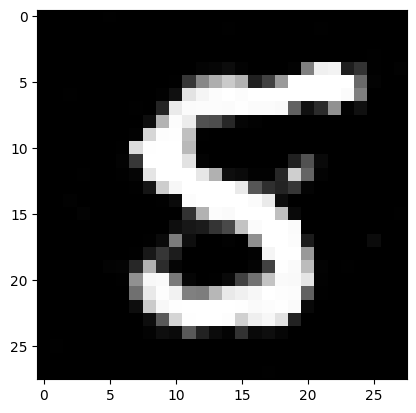

In [32]:
import matplotlib.pyplot as plt

with torch.no_grad():
    test_z = Variable(torch.randn(bs, z_dim).to(device))
    generated = G(test_z)

    # Show the image
    img = generated.view(generated.size(0), 1, 28, 28)
    img = img.detach().cpu()  # move the generated tensor to cpu
    plt.imshow(img[0][0], cmap='gray')
    plt.show()

    